# Assignment 3: Soft-Prompt Tuning, Chain of Thought and Critique Fine-Tuning

Foundation of Large Language Models (AI60213), 20 marks.

Read the assignment handout. Complete the designated functions and keep execution outputs. Write a separate report and submit the exported results.json with the notebook and PDF in one ZIP.


In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"
print(os.environ.get("CUDA_VISIBLE_DEVICES"))

1


In [2]:
import subprocess
import sys
import torch
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (FP32)")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                "transformers==4.57.1", "accelerate==1.10.1", "datasets==3.6.0",
                "matplotlib", "pandas"], check=True)


Device: NVIDIA L40


CompletedProcess(args=['/home/shivraj-pg/miniconda3/envs/assignment/bin/python', '-m', 'pip', 'install', '--quiet', 'transformers==4.57.1', 'accelerate==1.10.1', 'datasets==3.6.0', 'matplotlib', 'pandas'], returncode=0)

## Utilities and dataset
Download the supplied `assignment3_data.json` and set `DATA_PATH` in the data cell. Use the course file unchanged; no other edits to these supplied cells are needed.

In [3]:
import json
import gc
import hashlib
import math
import random
import re
import time
import contextlib
from decimal import Decimal, InvalidOperation
from itertools import islice
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

NUMBER_PATTERN = r"[-+]?(?:(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?|\.\d+)"
INIT_TEXT = "Solve the arithmetic problem accurately."

TASKS = ("direct", "cot", "critique")
SOLVE_CONDITIONS = ("frozen_direct", "frozen_cot", "tuned_direct", "tuned_cot", "tuned_cft_cot")
CRITIC_CONDITIONS = ("frozen_critic", "tuned_critic")
CRITIQUE_SCORER_VERSION = "2-independent-verdict-and-location"
RESULTS_SCHEMA_VERSION = 3


def configuration():
    return dict(seed=42, model="Qwen/Qwen2.5-0.5B-Instruct",
                model_revision="7ae557604adf67be50417f59c2c2f167def9a775",
                n_train=500, n_val=50, n_test=100, epochs=3,
                virtual_tokens=20, max_seq_length=768, train_batch_size=2,
                gradient_accumulation=8, eval_batch_size=4, learning_rate=3e-3,
                weight_decay=0.0, max_grad_norm=1.0, max_new_tokens=512,
                critic_max_new_tokens=256, do_sample=False, num_beams=1,
                repetition_penalty=1.0, no_repeat_ngram_size=0, device="auto")


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n")


def write_jsonl(path, rows):
    Path(path).write_text("".join(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n" for row in rows))


def load_course_data(payload, cfg):
    """Load balanced splits in source order and check question separation."""
    result = {}
    seen = set()
    for split, key in (("train", "n_train"), ("validation", "n_val"), ("test", "n_test")):
        count = cfg[key]
        if not isinstance(count, int) or count <= 0 or count % 2:
            raise ValueError("Split size must be a positive even integer")
        source = payload["splits"][split]
        rows = []
        for verdict in ("CORRECT", "INCORRECT"):
            rows.extend([e for e in source if e["verdict"] == verdict][:count // 2])
        if len(rows) != count:
            raise ValueError("Requested split exceeds the supplied bank")
        # Preserve the order of the selected records in the supplied dataset.
        ids = {e["source_id"] for e in rows}
        rows = [dict(e) for e in source if e["source_id"] in ids]
        for e in rows:
            if e["question_id"] in seen:
                raise ValueError("A question appears more than once or in multiple splits")
            seen.add(e["question_id"])
        result[split] = rows
    return result


def export_results(path, cfg, results, histories, predictions, pairs):
    if set(predictions) != set(SOLVE_CONDITIONS + CRITIC_CONDITIONS):
        raise ValueError("Export requires all seven conditions")
    expected = None
    for condition, rows in predictions.items():
        ids = {r["source_id"] for r in rows}
        if len(rows) != cfg["n_test"] or len(ids) != len(rows):
            raise ValueError(f"Wrong prediction count or duplicate IDs: {condition}")
        if expected is None:
            expected = ids
        elif ids != expected:
            raise ValueError("Conditions must use the same test question IDs")
    payload = dict(schema_version=RESULTS_SCHEMA_VERSION, critique_scorer_version=CRITIQUE_SCORER_VERSION,
                   configuration=cfg, results=results,
                   histories=histories, predictions=predictions, pairs=pairs)
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    write_json(path, payload)
    return path


def generate_from_embeddings(model, batch, max_new_tokens, pad_id):
    """Return new IDs only for the supplied soft-prompt model."""
    return model.base.generate(**model.prepend(batch["input_ids"], batch["attention_mask"]),
                               do_sample=False, num_beams=1, use_cache=True,
                               max_new_tokens=max_new_tokens, pad_token_id=pad_id)





def numeric_answer(text):
    """Require a final #### number, rather than guessing from intermediate math."""
    if "####" not in text:
        return None
    answer = text.rsplit("####", 1)[-1].strip()
    # Reject fractions, extra prose, and malformed commas instead of accepting
    # their numeric prefix. Accept ordinary decimal GSM8K answer formats.
    if re.fullmatch(NUMBER_PATTERN, answer) is None:
        return None
    try:
        number = Decimal(answer.replace(",", ""))
        return "0" if number == 0 else str(number.normalize())
    except InvalidOperation:
        return None

def display_number(value):
    """Conservative scalar extraction; never consults the reference answer.

    Supports decimal numbers, a short list of units, and English integers 0--99.
    Fractions, expressions, and arbitrary number-bearing prose are rejected.
    """
    value = value.strip().rstrip(".! ").strip()
    # Presentation wrappers around a scalar are not part of its value. Only
    # unwrap a complete number; never evaluate expressions or fractions.
    value = re.sub(r"\\\(\s*(" + NUMBER_PATTERN + r")\s*\\\)", r"\1", value)
    emphasis = re.fullmatch(r"\*\*(.+)\*\*", value)
    if emphasis:
        value = emphasis[1].strip()
    if value.startswith("$"):
        value = value[1:].strip()
    units = (r"(?:dollars?|cents?|years?|days?|weeks?|months?|hours?|minutes?|seconds?|"
             r"inches|inch|feet|foot|pounds?|boxes|apples?|people|degrees?|kg|mm|cm|WPM|%)")
    value = re.sub(r"\s*" + units + r"$", "", value, flags=re.IGNORECASE).strip()
    number = numeric_answer("#### " + value)
    if number is not None:
        return number
    ones = "zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen".split()
    tens = {name: 10 * i for i, name in enumerate(
        "zero ten twenty thirty forty fifty sixty seventy eighty ninety".split()) if i >= 2}
    parts = value.lower().replace("-", " ").split()
    if len(parts) == 1 and parts[0] in ones:
        return numeric_answer("#### " + str(ones.index(parts[0])))
    if len(parts) in (1, 2) and parts[0] in tens:
        if len(parts) == 1 or parts[1] in ones[1:10]:
            n = tens[parts[0]] + (ones.index(parts[1]) if len(parts) == 2 else 0)
            return numeric_answer("#### " + str(n))
    return None

def extracted_answer(text, hit_token_limit=False):
    """Diagnostic final-answer heuristic, not a grader of reasoning correctness."""
    strict = numeric_answer(text)
    if strict is not None:
        return strict, "strict"
    if "####" in text:
        tail = text.rsplit("####", 1)[-1].strip()
        line = tail.splitlines()
        if line and re.fullmatch(r"(?:conclusion|final answer|answer|number):?", line[0], re.IGNORECASE):
            # Markdown headings are not numeric answer markers. Only inspect
            # their following content, never an earlier intermediate answer.
            text = "\n".join(line[1:])
        else:
            # A malformed last answer marker must not fall back to an earlier calculation.
            answer = display_number(line[0]) if line else None
            if answer is not None:
                # A valid early marker can be explicitly corrected later. Prefer
                # the later boxed answer, independently of either value's gold.
                later_boxed = re.findall(r"\\boxed\{([^{}]+)\}", tail)
                if later_boxed:
                    final = display_number(later_boxed[-1])
                    return final, "boxed" if final is not None else "none"
            return answer, "marker_line" if answer is not None else "none"
    boxed = re.findall(r"\\boxed\{([^{}]+)\}", text)
    if boxed:
        answer = display_number(boxed[-1])
        return answer, "boxed" if answer is not None else "none"
    # Unmarked unfinished reasoning must not be scored by its last intermediate number.
    if not hit_token_limit:
        final_line = text.strip().splitlines()[-1] if text.strip() else ""
        bold = list(re.finditer(r"\*\*([^*\n]+)\*\*", final_line))
        lines = [line.strip() for line in text.strip().splitlines() if line.strip()]
        heading = (len(lines) >= 2 and re.fullmatch(
            r"#{1,6}\s*(?:conclusion|final answer|answer):?", lines[-2], re.IGNORECASE))
        if (re.match(r"^(?:therefore|thus|so)\b", final_line, re.IGNORECASE) or heading) and len(bold) == 1:
            match = bold[0]
            outside = final_line[:match.start()] + final_line[match.end():]
            # A single emphasized scalar in a final conclusion may have trailing
            # prose. Reject competing values, arithmetic, negation or alternatives.
            if not re.search(r"\d|[=+*/<>]|\b(?:not|or|instead|rather|versus|compare)\b",
                             outside, re.IGNORECASE):
                answer = display_number(match[1])
                if answer is not None:
                    return answer, "bold_conclusion"
        statements = list(re.finditer(r"(?:\bis\b|\bwas\b|\bequals\b|=)\s*", text, re.IGNORECASE))
        for match in reversed(statements):
            answer = display_number(text[match.end():])
            if answer is not None:
                return answer, "final_statement"
        answer = display_number(text)
        if answer is not None:
            return answer, "bare_answer"
    return None, "none"

def score_response(response, reference, hit_token_limit=False):
    strict = numeric_answer(response)
    extracted, method = extracted_answer(response, hit_token_limit)
    return {"prediction": strict, "reference": reference,
            "correct": strict is not None and strict == reference,
            "extracted_prediction": extracted, "extraction_method": method,
            "extracted_correct": extracted is not None and extracted == reference,
            "format_compliant": strict is not None}

def check_scorer_examples():
    """Supplied metric examples; these checks do not assess reasoning quality."""
    cases = [
        ("#### 42", "42", True),
        ("#### 42.", "42", False),
        ("The answer is: 42.", None, False),
        ("Work first.\n#### 42", "42", True),
        ("#### 42\nActually, the correct answer is 41.", "42", False),
        ("Unfinished: 6 times 7", None, False),
    ]
    for response, extracted, compliant in cases:
        scored = score_response(response, "42")
        assert scored["extracted_prediction"] == extracted, response
        assert scored["format_compliant"] == compliant, response
    print(f"Scorer examples: {len(cases)} passed.")

def groups(iterable, size):
    iterator = iter(iterable)
    while batch := list(islice(iterator, size)):
        yield batch


def load_model(cfg):
    requested = cfg.get("device", "auto")
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") if requested == "auto" else torch.device(requested)
    if device.type not in {"cpu", "cuda"}:
        raise ValueError("This loader supports CPU (FP32) and CUDA (FP16); choose device='auto', 'cpu' or 'cuda:0'.")
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is unavailable; select a GPU runtime or set device='cpu'.")
    model = AutoModelForCausalLM.from_pretrained(
        cfg["model"], revision=cfg["model_revision"],
        dtype=torch.float16 if device.type == "cuda" else torch.float32,
        attn_implementation="sdpa",
    ).to(device)
    # inputs_embeds has no prompt token-ID history in the pinned Transformers.
    # Neutralize history-dependent penalties for comparable frozen/tuned decoding.
    model.generation_config.do_sample = cfg["do_sample"]
    model.generation_config.num_beams = cfg["num_beams"]
    model.generation_config.repetition_penalty = cfg["repetition_penalty"]
    model.generation_config.no_repeat_ngram_size = cfg["no_repeat_ngram_size"]
    model.generation_config.temperature = None
    model.generation_config.top_p = None
    model.generation_config.top_k = None
    print("Model device:", device, "base dtype:", next(model.parameters()).dtype)
    return model

def default_output_root():
    """Writable notebook working directory on Kaggle, Colab or a local runtime."""
    root = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
    return root / "assignment3"

def eos_ids(model, tokenizer):
    value = model.generation_config.eos_token_id
    if value is None:
        value = tokenizer.eos_token_id
    return set(value if isinstance(value, list) else [value])



/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Download the supplied course JSON and set its location here.
# Kaggle: attach it as a dataset; Colab: upload it to the session.
DATA_PATH = Path("assignment3_data.json")
DATA_SHA256 = '4ef1b58f05217a72e0343564a9d4b7988ec8646c064f424f959ed956506dc68a'
if not DATA_PATH.is_file():
    raise FileNotFoundError("Download assignment3_data.json and set DATA_PATH to its location.")
if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != DATA_SHA256:
    raise ValueError("Use the unchanged assignment3_data.json supplied with this assignment.")
with DATA_PATH.open(encoding="utf-8") as handle:
    COURSE_DATA = json.load(handle)


## Q1. Data pipeline (3 marks)
Implement the functions as specified in the handout.

In [5]:
def prompt_text(tokenizer, example, task):
    """Q1a: format the specified task prompt using allowed input fields only."""
    ## CODE HERE ##
    # raise NotImplementedError('prompt_text')
    
    system_prompt = "You solve arithmetic word problems accurately."
    
    if task=='direct':
        user_prompt = f"{example['question']}\n\nGive only the final answer in the form #### number."
    elif task=='cot':
        user_prompt = f"{example['question']}\n\nShow a short step-by-step solution. End with #### number."
    elif task=='critique':
        user_prompt = (
            f"Question:\n{example['question']}\n\n"
            f"Candidate solution:\n{example['candidate']}\n\n"
            "Check the reasoning, not only the final answer. "
            "Use exactly this format:\n"
            "VERDICT: CORRECT or INCORRECT\n"
            "FIRST_ERROR: NONE or a positive step number\n"
            "EXPLANATION: Explain the first error, or state that no error was found."
        )
    else:
        raise ValueError(f"Unknown Task {task} entered")
        
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt = True 
    )

def target_text(example, task):
    """Q1a: construct and validate the direct, CoT or critique target."""
    ## CODE HERE ##
    # raise NotImplementedError('target_text')
    if task == "direct":
        answer = example["answer"]

        if "####" not in answer:
            raise ValueError("Answer is missing the #### final-answer marker.")

        rationale, final = answer.rsplit("####", 1)
        final = final.strip()

        if re.fullmatch(NUMBER_PATTERN, final) is None:
            raise ValueError(f"Invalid final numeric answer: {final}")

        final_answer = f"#### {final}"
        
        return final_answer
    
    elif task == 'cot':
        
        answer = example["answer"]

        if "####" not in answer:
            raise ValueError("Answer is missing the #### final-answer marker.")

        rationale, final = answer.rsplit("####", 1)
        final = final.strip()

        if re.fullmatch(NUMBER_PATTERN, final) is None:
            raise ValueError(f"Invalid final numeric answer: {final}")

        final_answer = f"#### {final}"
        rationale = re.sub(r"<<.*?>>", "", rationale).strip()

        if not rationale:
            raise ValueError("CoT rationale cannot be empty.")

        return rationale + "\n" + final_answer       

    elif task == "critique":
        verdict = example["verdict"]
        first_error = example["first_error"]
        num_steps = example["num_steps"]
        explanation = example["critique"].strip()

        if verdict not in ("CORRECT", "INCORRECT"):
            raise ValueError(f"Invalid verdict: {verdict}")

        if not isinstance(num_steps, int) or num_steps <= 0:
            raise ValueError("num_steps must be a positive integer.")

        if not explanation:
            raise ValueError("Critique explanation cannot be empty.")

        if verdict == "CORRECT":
            if first_error is not None:
                raise ValueError("CORRECT examples must have first_error=None.")
            error_text = "NONE"

        else:
            if (not isinstance(first_error, int)
                    or isinstance(first_error, bool)
                    or not 1 <= first_error <= num_steps):
                raise ValueError("INCORRECT examples require a valid first_error.")
            error_text = str(first_error)

        return (
            f"VERDICT: {verdict}\n"
            f"FIRST_ERROR: {error_text}\n"
            f"EXPLANATION: {explanation}"
        )

    else:
        raise ValueError(f"Unknown task: {task}")

def training_record(tokenizer, example, task):
    """Q1b: construct causal input_ids and response-only labels."""
    ## CODE HERE ##
    # raise NotImplementedError('training_record')
    prefix = tokenizer.encode(prompt_text(tokenizer, example, task), add_special_tokens=False)
    target = tokenizer.encode(target_text(example, task), add_special_tokens=False)
    eos_id = tokenizer.eos_token_id
    if eos_id is None:
        raise ValueError("Tokenizer has no EOS token.")
    target = target + [eos_id]

    total = cfg['virtual_tokens'] + len(prefix) + len(target)
    if total > cfg['max_seq_length']:                       # FIX 3: never truncate silently
        raise ValueError(f"{task} record {example.get('source_id')} needs {total} tokens "
                         f"(> {cfg['max_seq_length']} incl. {cfg['virtual_tokens']} virtual); refusing to truncate.")

    return {"input_ids": prefix + target,
            "labels": [-100] * len(prefix) + target}


def collate_training(records, pad_id):
    """Q1c: dynamically right-pad records and mask by position."""
    ## CODE HERE ##
    # raise NotImplementedError('collate_training')
    if not records:
        raise ValueError("Cannot collate an empty batch.")

    max_length = max(len(record["input_ids"]) for record in records)

    input_ids = []
    attention_mask = []
    labels = []

    for record in records:
        ids = record["input_ids"]
        target_labels = record["labels"]

        if len(ids) != len(target_labels):
            raise ValueError("input_ids and labels must have equal lengths.")

        padding_length = max_length - len(ids)

        input_ids.append(ids + [pad_id] * padding_length)
        attention_mask.append([1] * len(ids) + [0] * padding_length)
        labels.append(target_labels + [-100] * padding_length)

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long),
    }
    
    

## Q2. Input soft prompt (4 marks)
Implement the functions as specified in the handout.

In [6]:
class SoftPromptLM(torch.nn.Module):

    def __init__(self, base, tokenizer, num_tokens=20):
        """Q2a: freeze the base and initialize the independent FP32 input prompt."""
        ## CODE HERE ##
        # raise NotImplementedError('__init__')
        
        super().__init__()

        self.base = base
        self.tokenizer = tokenizer
        self.num_tokens = num_tokens

        if num_tokens <= 0:
            raise ValueError("num_tokens must be positive.")

        for param in self.base.parameters():
            param.requires_grad = False

        embedding_layer = self.base.get_input_embeddings()
        embedding_dim = embedding_layer.weight.shape[1]

        init_ids = tokenizer.encode(INIT_TEXT, add_special_tokens=False)

        if not init_ids:
            raise ValueError("INIT_TEXT produced no tokens.")

        repeated_ids = (init_ids * math.ceil(num_tokens / len(init_ids)))[:num_tokens]

        init_ids_tensor = torch.tensor(
            repeated_ids,
            dtype=torch.long,
            device=embedding_layer.weight.device,
        )

        with torch.no_grad():
            initial_prompt = embedding_layer(init_ids_tensor).detach().float()

        self.prompt = torch.nn.Parameter(initial_prompt.clone())

        assert self.prompt.shape == (num_tokens, embedding_dim)
        assert self.prompt.dtype == torch.float32

    def prepend(self, input_ids, attention_mask, labels=None):
        """Q2b: construct augmented embeddings, masks and optional labels."""
        ## CODE HERE ##
        # raise NotImplementedError('prepend')
        if input_ids.ndim != 2 or attention_mask.shape != input_ids.shape:
            raise ValueError("input_ids and attention_mask must have matching [B, L] shapes.")

        batch_size, seq_length = input_ids.shape

        embedding_layer = self.base.get_input_embeddings()
        input_embeddings = embedding_layer(input_ids)

        prompt_embeddings = self.prompt.unsqueeze(0).expand(batch_size, -1, -1)
        prompt_embeddings = prompt_embeddings.to(dtype=input_embeddings.dtype)

        inputs_embeds = torch.cat([prompt_embeddings, input_embeddings], dim=1,)

        prompt_mask = torch.ones(
            batch_size,
            self.num_tokens,
            dtype=attention_mask.dtype,
            device=attention_mask.device,
        )

        augmented_attention_mask = torch.cat([prompt_mask, attention_mask], dim=1)

        output = {
            "inputs_embeds": inputs_embeds,
            "attention_mask": augmented_attention_mask,
        }

        # FIX 2: do NOT return position_ids. generate() never extends a user-supplied
        # position_ids tensor, so every generated token would reuse the last prompt
        # position. HF derives correct positions from attention_mask / cache_position.

        if labels is not None:
            if labels.shape != input_ids.shape:
                raise ValueError("labels must have the same shape as input_ids.")

            prompt_labels = torch.full(
                (batch_size, self.num_tokens),
                -100,
                dtype=labels.dtype,
                device=labels.device,
            )

            output["labels"] = torch.cat([prompt_labels, labels], dim=1)

        return output


    def forward(self, input_ids, attention_mask, labels=None):
        """Q2c: return the base output with causal loss and no training cache."""
        ## CODE HERE ##
        # raise NotImplementedError('forward')
        inputs = self.prepend(input_ids, attention_mask, labels)
        return self.base(**inputs, use_cache=False)


## Q3. Training loop (4 marks)
Implement the functions as specified in the handout.

In [7]:
def fit_prompt(model, records, tokenizer, validation, task, cfg, out):
    """Q3: implement token-weighted training, validation and checkpoint saving."""
    ## CODE HERE ##
    # raise NotImplementedError('fit_prompt')
    seed = cfg["seed"]
    random.seed(seed)
    torch.manual_seed(seed)
    device = next(model.base.parameters()).device
    use_cuda = device.type == "cuda"
    if use_cuda:
        torch.cuda.manual_seed_all(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)        

    batch_size = cfg["train_batch_size"]
    accumulation_steps = cfg["gradient_accumulation"]
    epochs = cfg["epochs"]
    max_grad_norm = cfg["max_grad_norm"]
    if accumulation_steps < 1 or batch_size < 1 or epochs < 1:
        raise ValueError("Invalid training configuration.")

    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id

    loader = torch.utils.data.DataLoader(
        records, batch_size=batch_size, shuffle=True, generator=generator,
        collate_fn=lambda rows: collate_training(rows, pad_id), drop_last=False)

    optimizer = torch.optim.AdamW([model.prompt], lr=cfg["learning_rate"],
                                  weight_decay=cfg["weight_decay"])
    scaler = torch.amp.GradScaler("cuda") if use_cuda else None

    def supervised(batch):
        return int((batch["labels"][:, 1:] != -100).sum().item())

    history = []
    for epoch in range(epochs):
        model.train()
        model.base.eval()
        loss_sum, token_sum = 0.0, 0
        max_norm_seen, updates, skipped = 0.0, 0, 0
        optimizer.zero_grad(set_to_none=True)

        batches = list(loader)                     
        for start in range(0, len(batches), accumulation_steps):
            window = batches[start:start + accumulation_steps] 
            window_tokens = sum(supervised(b) for b in window)
            if window_tokens == 0:
                raise ValueError("Accumulation window without supervised tokens.")

            for batch in window:
                batch = {k: v.to(device) for k, v in batch.items()}
                n_tok = supervised(batch)
                ctx = (torch.autocast(device_type="cuda", dtype=torch.float16)
                       if use_cuda else contextlib.nullcontext())
                with ctx:
                    loss = model(input_ids=batch["input_ids"],
                                 attention_mask=batch["attention_mask"],
                                 labels=batch["labels"]).loss
                if not torch.isfinite(loss):
                    raise FloatingPointError("Non-finite training loss.")

                weighted = loss * (n_tok / window_tokens)
                (scaler.scale(weighted) if scaler is not None else weighted).backward()

                loss_sum += loss.detach().float().item() * n_tok
                token_sum += n_tok

            if scaler is not None:
                scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_([model.prompt], max_grad_norm)
            finite = bool(torch.isfinite(grad_norm))
            if scaler is not None:
                before = scaler.get_scale()
                scaler.step(optimizer)         
                scaler.update()
                if scaler.get_scale() < before:
                    skipped += 1      
            else:
                if not finite:
                    raise FloatingPointError("Non-finite gradient norm.")
                optimizer.step()
            if finite:
                max_norm_seen = max(max_norm_seen, float(grad_norm))
            updates += 1
            optimizer.zero_grad(set_to_none=True)

        response_token_loss = loss_sum / token_sum

        model.eval()
        with torch.no_grad():
            if task in ("direct", "cot"):
                rows = evaluate_model(model, tokenizer, validation, task, cfg)
                metric = summarize_predictions(rows)["numeric_accuracy"]
                metric_name = "numeric_accuracy"
            elif task == "critique":
                rows = evaluate_critic(model, tokenizer, validation, cfg)
                metric = summarize_critiques(rows)["balanced_accuracy"]
                metric_name = "balanced_accuracy"
            else:
                raise ValueError(f"Unknown task {task}")

        history.append({"epoch": epoch + 1,
                        "response_token_loss": float(response_token_loss),
                        "validation_metric": float(metric),
                        "validation_metric_name": metric_name})
        print(f"{task} | epoch {epoch + 1}/{epochs} | response-token loss {response_token_loss:.6f} | "
              f"{metric_name} {metric:.4f} | updates {updates} (skipped by scaler: {skipped}) | "
              f"max finite grad-norm {max_norm_seen:.4f}")

    print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
    print("Base frozen:", all(not p.requires_grad for p in model.base.parameters()),
          "| base grads None:", all(p.grad is None for p in model.base.parameters()))

    if out is not None:
        out_dir = Path(out)
        out_dir.mkdir(parents=True, exist_ok=True)
        torch.save(model.prompt.detach().cpu(), out_dir / f"{task}_prompt.pt")
        write_json(out_dir / f"{task}_history.json", history)
    return history


## Q4. Generation and solving evaluation (2 marks)
Implement the functions as specified in the handout.

In [8]:
def generate_responses(model, tokenizer, examples, task, cfg):
    """Q4a: implement task-aware batched decoding and EOS/token-cap accounting."""
    ## CODE HERE ##
    # raise NotImplementedError('generate_responses')
    is_soft = hasattr(model, "prompt")
    base_model = model.base if is_soft else model
    device = next(base_model.parameters()).device
    max_new_tokens = cfg["critic_max_new_tokens"] if task == "critique" else cfg["max_new_tokens"]

    stop_ids = sorted(eos_ids(base_model, tokenizer))
    eos_arg = stop_ids[0] if len(stop_ids) == 1 else stop_ids
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    gc_ = base_model.generation_config
    gc_.eos_token_id, gc_.pad_token_id = eos_arg, pad_id
    gc_.do_sample, gc_.num_beams = cfg["do_sample"], cfg["num_beams"]
    gc_.repetition_penalty, gc_.no_repeat_ngram_size = cfg["repetition_penalty"], cfg["no_repeat_ngram_size"]

    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    model.eval()
    results = []
    try:
        with torch.no_grad():
            for batch_examples in groups(examples, cfg["eval_batch_size"]):
                prompts = [prompt_text(tokenizer, ex, task) for ex in batch_examples]
                enc = tokenizer(prompts, padding=True, return_tensors="pt", add_special_tokens=False)
                batch = {"input_ids": enc["input_ids"].to(device),
                         "attention_mask": enc["attention_mask"].to(device)}
                if is_soft:
                    generated = generate_from_embeddings(model, batch, max_new_tokens, pad_id)
                else:
                    out_ids = model.generate(**batch, max_new_tokens=max_new_tokens,
                                             do_sample=cfg["do_sample"], num_beams=cfg["num_beams"],
                                             repetition_penalty=cfg["repetition_penalty"],
                                             no_repeat_ngram_size=cfg["no_repeat_ngram_size"],
                                             eos_token_id=eos_arg, pad_token_id=pad_id, use_cache=True)
                    generated = out_ids[:, batch["input_ids"].shape[1]:]

                for ex, ids in zip(batch_examples, generated.tolist()):
                    pos = next((i for i, t in enumerate(ids) if t in stop_ids), None)
                    if pos is not None:
                        ids, hit = ids[:pos + 1], False          # count through first EOS only
                    else:
                        hit = len(ids) >= max_new_tokens        # limit reached without EOS
                    results.append({"source_id": ex["source_id"], "question_id": ex["question_id"],
                                    "question": ex["question"],
                                    "response": tokenizer.decode(ids, skip_special_tokens=True).strip(),
                                    "generated_tokens": len(ids), "hit_token_limit": hit})
    finally:
        tokenizer.padding_side = old_side
    return results


def evaluate_model(model, tokenizer, examples, task, cfg):
    """Q4a: score solving responses with the supplied number scorer."""
    ## CODE HERE ##
    # raise NotImplementedError('evaluate_model')

    if task not in ("direct", "cot"):
        raise ValueError("evaluate_model supports direct and cot only.")

    predictions = generate_responses(model, tokenizer, examples, task, cfg)

    scored_rows = []

    for example, row in zip(examples, predictions):
        reference = numeric_answer(example["answer"])
        scores = score_response(row["response"], reference, row["hit_token_limit"])
        scored_rows.append({**row, **scores})

    return scored_rows


def summarize_predictions(rows):
    """Q4b: aggregate solving metrics with input validation."""
    ## CODE HERE ##
    # raise NotImplementedError('summarize_predictions')
    if not rows:
        raise ValueError("Prediction rows cannot be empty.")

    ids = [row["source_id"] for row in rows]

    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate source IDs found.")

    n = len(rows)

    numeric_accuracy = sum(row["extracted_correct"] for row in rows)/n
    format_compliance = sum(row["format_compliant"] for row in rows)/n
    unparsed_rate = sum(row["extracted_prediction"] is None for row in rows)/n
    token_limit_rate = sum(row["hit_token_limit"] for row in rows)/n

    return {
        "examples": n,
        "numeric_accuracy": numeric_accuracy,
        "format_compliance": format_compliance,
        "unparsed_rate": unparsed_rate,
        "token_limit_rate": token_limit_rate,
    }


def paired_outcomes(before, after):
    """Q4b: match IDs and compute correctness-transition counts."""
    ## CODE HERE ##
    # raise NotImplementedError('paired_outcomes')

    if not before or not after:
        raise ValueError("Both prediction sets must be non-empty.")

    before_ids = [row["source_id"] for row in before]
    after_ids = [row["source_id"] for row in after]

    if len(before_ids) != len(set(before_ids)):
        raise ValueError("Duplicate IDs in before predictions.")

    if len(after_ids) != len(set(after_ids)):
        raise ValueError("Duplicate IDs in after predictions.")

    before_map = {row["source_id"]: row for row in before}
    after_map = {row["source_id"]: row for row in after}

    if set(before_map) != set(after_map):
        raise ValueError("Before and after prediction IDs do not match.")

    both_correct = 0
    fixed = 0
    broken = 0
    both_wrong = 0

    for source_id in before_map:

        old = before_map[source_id]
        new = after_map[source_id]

        if old["question"] != new["question"]:
            raise ValueError(f"Question mismatch for {source_id}.")

        if old["reference"] != new["reference"]:
            raise ValueError(f"Reference mismatch for {source_id}.")

        old_correct = old["extracted_correct"]
        new_correct = new["extracted_correct"]

        if old_correct and new_correct:
            both_correct += 1
        elif not old_correct and new_correct:
            fixed += 1
        elif old_correct and not new_correct:
            broken += 1
        else:
            both_wrong += 1

    n = len(before)
    before_accuracy = sum(row["extracted_correct"] for row in before)/n
    after_accuracy = sum(row["extracted_correct"] for row in after)/n
    paired_accuracy_change = (fixed - broken) / n

    assert math.isclose(
        after_accuracy - before_accuracy,
        paired_accuracy_change,
        abs_tol=1e-12,
    )

    return {
        "both_correct": both_correct,
        "fixed": fixed,
        "broken": broken,
        "both_wrong": both_wrong,
    }


## Q5. Critique evaluation and transfer (5 marks)
Implement the functions as specified in the handout.

In [9]:
def parse_critique(response, num_steps):
    """Q5a: implement the critique output contract without references; retain field validity independently."""
    ## CODE HERE ##
    # raise NotImplementedError('parse_critique')

    if not isinstance(num_steps, int) or isinstance(num_steps, bool) or num_steps <= 0:
        raise ValueError("num_steps must be a positive integer.")

    text = response.strip()
    lines = text.splitlines()

    header_pattern = re.compile(r"^\s*(VERDICT|FIRST_ERROR|EXPLANATION)\s*:", re.IGNORECASE)

    header_names = [match.group(1).upper() for line in lines if (match := header_pattern.match(line))]

    unique_headers = (
        len(header_names) == 3
        and set(header_names) == {"VERDICT", "FIRST_ERROR", "EXPLANATION"}
        and len(header_names) == len(set(header_names))
    )

    verdict = None

    verdict_matches = [i for i, line in enumerate(lines) if re.match(r"^\s*VERDICT\s*:", line, re.IGNORECASE)]

    if (len(verdict_matches) == 1 and verdict_matches[0] == 0):
        match = re.fullmatch(r"VERDICT:\s*(CORRECT|INCORRECT)\s*", lines[0])
        if match:
            verdict = match.group(1)

    first_error = None
    first_error_valid = False

    error_matches = [i for i, line in enumerate(lines) if re.match(r"^\s*FIRST_ERROR\s*:", line, re.IGNORECASE)]

    if (verdict is not None and len(error_matches) == 1 and error_matches[0] == 1):
        match = re.fullmatch(r"FIRST_ERROR:\s*(NONE|[0-9]+)\s*", lines[1])

        if match:
            value = match.group(1)

            if verdict == "CORRECT" and value == "NONE":
                first_error = None
                first_error_valid = True

            elif verdict == "INCORRECT" and re.fullmatch(r"[1-9][0-9]*", value):
                step = int(value)

                if step <= num_steps:
                    first_error = step
                    first_error_valid = True

    explanation = None
    format_compliant = False

    if (
        len(lines) >= 3
        and verdict is not None
        and first_error_valid
        and unique_headers
        and lines[2].startswith("EXPLANATION:")
        and not any("```" in line for line in lines)
    ):
        explanation_text = lines[2][len("EXPLANATION:"):].strip()

        if len(lines) > 3:
            explanation_text += "\n" + "\n".join(lines[3:]).strip()

        explanation_text = explanation_text.strip()

        if explanation_text:
            explanation = explanation_text
            format_compliant = True

    return {
        "verdict": verdict,
        "first_error": first_error,
        "first_error_valid": first_error_valid,
        "explanation": explanation,
        "format_compliant": format_compliant,
    }


def score_critique(response, num_steps, reference_verdict, reference_first_error):
    """Q5b: validate references and score verdict and first-error agreement."""
    ## CODE HERE ##
    # raise NotImplementedError('score_critique')

    if reference_verdict not in ("CORRECT", "INCORRECT"):
        raise ValueError("Invalid reference verdict.")

    if reference_verdict == "CORRECT":
        if reference_first_error is not None:
            raise ValueError("A CORRECT reference must have first_error=None.")

    else:
        if (
            not isinstance(reference_first_error, int)
            or isinstance(reference_first_error, bool)
            or not 1 <= reference_first_error <= num_steps
        ):
            raise ValueError(
                "An INCORRECT reference must have a valid first-error step."
            )

    parsed = parse_critique(response, num_steps)

    verdict_correct = parsed["verdict"] == reference_verdict

    joint_correct = (verdict_correct and parsed["first_error_valid"] and parsed["first_error"] == reference_first_error)

    return {
        **parsed,
        "reference_verdict": reference_verdict,
        "reference_first_error": reference_first_error,
        "verdict_correct": verdict_correct,
        "joint_correct": joint_correct,
    }


def summarize_critiques(rows):
    """Q5c: compute class recalls, invalid counts and localization metrics."""
    ## CODE HERE ##
    # raise NotImplementedError('summarize_critiques')

    if not rows:
        raise ValueError("Critique rows cannot be empty.")

    ids = [row["source_id"] for row in rows]

    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate source IDs found.")

    correct_rows = [row for row in rows if row["reference_verdict"] == "CORRECT"]
    incorrect_rows = [row for row in rows if row["reference_verdict"] == "INCORRECT"]

    if not correct_rows or not incorrect_rows:
        raise ValueError("Evaluation set must contain both CORRECT and INCORRECT references.")

    n = len(rows)

    def predicted_class(row):
        verdict = row["verdict"]
        return verdict if verdict in ("CORRECT", "INCORRECT") else "INVALID"

    confusion = {
        f"{actual}_{predicted}": 0
        for actual in ("CORRECT", "INCORRECT")
        for predicted in ("CORRECT", "INCORRECT", "INVALID")
    }

    for row in rows:
        actual = row["reference_verdict"]
        predicted = predicted_class(row)
        confusion[f"{actual}_{predicted}"] += 1

    correct_recall = confusion["CORRECT_CORRECT"]/len(correct_rows)
    incorrect_recall = confusion["INCORRECT_INCORRECT"]/len(incorrect_rows)
    verdict_accuracy = sum(row["verdict_correct"] for row in rows)/n
    balanced_accuracy = (correct_recall + incorrect_recall)/2
    false_rejection_rate = sum(row["verdict"]=="INCORRECT" for row in correct_rows)/len(correct_rows)
    correct_invalid_rate = sum(row["verdict"] is None for row in correct_rows)/len(correct_rows)
    first_error_accuracy = sum(row["joint_correct"] for row in incorrect_rows)/len(incorrect_rows)
    joint_accuracy = sum(row["joint_correct"] for row in rows)/n
    format_compliance = sum(row["format_compliant"] for row in rows)/n
    token_limit_rate = sum(row["hit_token_limit"] for row in rows)/n

    return {
        "examples": n,
        "verdict_accuracy": verdict_accuracy,
        "balanced_accuracy": balanced_accuracy,
        "correct_recall": correct_recall,
        "incorrect_recall": incorrect_recall,
        "false_rejection_rate": false_rejection_rate,
        "correct_invalid_rate": correct_invalid_rate,
        "first_error_accuracy": first_error_accuracy,
        "joint_accuracy": joint_accuracy,
        "format_compliance": format_compliance,
        "token_limit_rate": token_limit_rate,
        "confusion": confusion,
    }


def evaluate_critic(model, tokenizer, examples, cfg):
    """Q5d: generate critiques, then attach references and scores."""
    ## CODE HERE ##
    # raise NotImplementedError('evaluate_critic')

    predictions = generate_responses(model, tokenizer, examples, "critique", cfg)
    scored_rows = []
    for example, row in zip(examples, predictions):

        scores = score_critique(
            row["response"],
            example["num_steps"],
            example["verdict"],
            example["first_error"],
        )

        scored_rows.append({
            **row,
            "candidate": example["candidate"],
            "num_steps": example["num_steps"],
            "reference_explanation": example["critique"],
            **scores,
        })

    return scored_rows


def run_study(cfg, tokenizer, payload, out):
    """Q5e: independently train three prompts and evaluate seven conditions."""
    ## CODE HERE ##
    # raise NotImplementedError('run_study')

    splits = load_course_data(payload, cfg)

    train_data = splits["train"]
    validation = splits["validation"]
    test_data = splits["test"]

    print("Configuration:")
    print(json.dumps(cfg, indent=2))

    print("\nSplit sizes:")
    print({
        "train": len(train_data),
        "validation": len(validation),
        "test": len(test_data),
    })

    train_records = {
        task: [training_record(tokenizer, ex, task) for ex in train_data]
        for task in TASKS
    }
    for task in TASKS:
        recs = train_records[task]
        if len(recs) != len(train_data):
            raise ValueError(f"Missing training records for {task}.")
        for r in recs:
            if len(r["input_ids"]) != len(r["labels"]):
                raise ValueError("input_ids / labels length mismatch")
            if len(r["input_ids"]) + cfg["virtual_tokens"] > cfg["max_seq_length"]:
                raise ValueError(f"{task}: record exceeds max_seq_length")
        lens = [len(r["input_ids"]) + cfg["virtual_tokens"] for r in recs]
        tgt = [sum(l != -100 for l in r["labels"]) for r in recs]
        print(f"{task}: {len(recs)} records | total len max {max(lens)} mean {sum(lens)/len(lens):.1f} | "
              f"supervised tokens mean {sum(tgt)/len(tgt):.1f} max {max(tgt)}")

    base = load_model(cfg)
    model = SoftPromptLM(base, tokenizer, num_tokens=cfg["virtual_tokens"])

    initial_prompt = model.prompt.detach().clone()

    histories = {}
    learned_prompts = {}

    for task in TASKS:
        print(f"\n{'=' * 20} Training {task} {'=' * 20}")
        
        with torch.no_grad():
            model.prompt.copy_(initial_prompt)

        task_out = Path(out) / "training" if out is not None else None

        histories[task] = fit_prompt(
            model=model,
            records=train_records[task],
            tokenizer=tokenizer,
            validation=validation,
            task=task,
            cfg=cfg,
            out=task_out,
        )

        learned_prompts[task] = model.prompt.detach().cpu().clone()

    predictions = {}

    print("\nEvaluating frozen solving conditions...")

    predictions["frozen_direct"] = evaluate_model(base, tokenizer, test_data, "direct", cfg)
    predictions["frozen_cot"] = evaluate_model(base, tokenizer, test_data, "cot", cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["direct"].to(model.prompt.device))

    predictions["tuned_direct"] = evaluate_model(model, tokenizer, test_data, "direct", cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["cot"].to(model.prompt.device))

    predictions["tuned_cot"] = evaluate_model(model, tokenizer, test_data, "cot", cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["critique"].to(model.prompt.device))

    predictions["tuned_cft_cot"] = evaluate_model(model, tokenizer, test_data, "cot", cfg)

    print("\nEvaluating frozen critic...")

    predictions["frozen_critic"] = evaluate_critic(base, tokenizer, test_data, cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["critique"].to(model.prompt.device))

    predictions["tuned_critic"] = evaluate_critic(model, tokenizer, test_data, cfg)

    results = {"solving": [], "critique": []}

    for condition in SOLVE_CONDITIONS:
        summary = summarize_predictions(predictions[condition])
        results["solving"].append({
            "condition": condition,
            **summary,
        })

    for condition in CRITIC_CONDITIONS:
        summary = summarize_critiques(predictions[condition])
        results["critique"].append({
            "condition": condition,
            **summary,
        })

    pairs = {
        "direct": paired_outcomes(
            predictions["frozen_direct"],
            predictions["tuned_direct"],
        ),
        "cot": paired_outcomes(
            predictions["frozen_cot"],
            predictions["tuned_cot"],
        ),
        "cft_transfer": paired_outcomes(
            predictions["frozen_cot"],
            predictions["tuned_cft_cot"],
        ),
    }

    print("\nTraining histories:")
    for task, history in histories.items():
        print(f"\n{task}:")
        print(history)

    print("\nSolving results:")
    print(pd.DataFrame(results["solving"]).to_string(index=False))

    print("\nCritique results:")
    print(pd.DataFrame(results["critique"]).to_string(index=False))

    print("\nPaired outcomes:")
    print(json.dumps(pairs, indent=2))

    return results, histories, predictions, pairs

## Q6. Figures and analysis (2 marks)
Implement the functions as specified in the handout.

In [10]:
def make_figures(results, histories, pairs, out):
    """Q6a: save/display the required tables and separate metric plots."""
    ## CODE HERE ##
    # raise NotImplementedError('make_figures')
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)

    solving_table = pd.DataFrame(results["solving"])
    critique_table = pd.DataFrame(results["critique"])
    paired_table = pd.DataFrame.from_dict(pairs, orient="index")
    paired_table.index.name = "comparison"
    paired_table = paired_table.reset_index()
    confusion_table = pd.DataFrame([{"condition": r["condition"], **r["confusion"]}
                                    for r in results["critique"]])
    # the nested confusion dict is shown separately, not inside the critique table
    critique_flat = critique_table.drop(columns=["confusion"])

    for name, table in (("solving_results", solving_table), ("critique_results", critique_flat),
                        ("paired_outcomes", paired_table), ("critique_confusion", confusion_table)):
        table.to_csv(out / f"{name}.csv", index=False)

    print("Solving results:");            display(solving_table)
    print("Critique results:");           display(critique_flat)
    print("Paired outcomes:");            display(paired_table)
    print("Critique confusion counts:");  display(confusion_table)

    # three separate training-loss panels (own figure each)
    for task in ("direct", "cot", "critique"):
        h = histories[task]
        ep = [r["epoch"] for r in h]
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.plot(ep, [r["response_token_loss"] for r in h], marker="o")
        ax.set_title(f"{task}: response-token training loss")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Mean loss per response token")
        ax.set_xticks(ep); ax.grid(True, alpha=0.3)
        fig.tight_layout(); fig.savefig(out / f"training_loss_{task}.png", dpi=200, bbox_inches="tight")
        plt.show()

    fig, ax = plt.subplots(figsize=(6, 4))
    for task in ("direct", "cot"):
        h = histories[task]
        ax.plot([r["epoch"] for r in h], [r["validation_metric"] for r in h], marker="o", label=task)
    ax.set_title("Solving validation numeric accuracy")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Numeric accuracy")
    ax.set_xticks([r["epoch"] for r in histories["direct"]]); ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout(); fig.savefig(out / "solving_validation_accuracy.png", dpi=200, bbox_inches="tight")
    plt.show()

    h = histories["critique"]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot([r["epoch"] for r in h], [r["validation_metric"] for r in h], marker="o")
    ax.set_title("Critique validation balanced accuracy")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Balanced accuracy")
    ax.set_xticks([r["epoch"] for r in h]); ax.grid(True, alpha=0.3)
    fig.tight_layout(); fig.savefig(out / "critique_validation_balanced_accuracy.png", dpi=200, bbox_inches="tight")
    plt.show()

    return solving_table, critique_flat, paired_table


## Implementation checks
Demonstrate masking/padding, trainable counts, prompt updates, frozen base weights and critique metric edge cases.

In [11]:
import copy

def run_implementation_checks(cfg, tokenizer, base, payload):
    """Q1-Q5 checks. Pass the tokenizer, a loaded base model and the course payload."""
    ex_all = payload["splits"]["train"]
    ex_c = next(e for e in ex_all if e["verdict"] == "CORRECT")
    ex_i = next(e for e in ex_all if e["verdict"] == "INCORRECT")
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
    eos = tokenizer.eos_token_id


    
    
    
    
    
    print("== Q1a prompts ==")
    for task in TASKS:
        p = prompt_text(tokenizer, ex_i, task)
        assert ex_i["question"] in p
        assert ("Candidate solution:" in p) == (task == "critique")
        assert ex_i["answer"] not in p and ex_i["critique"] not in p
        print(f"[{task}]\n{p}\n" + "-" * 60)
    for bad in ("nope",):
        try: prompt_text(tokenizer, ex_c, bad); raise SystemExit("unsupported task accepted")
        except ValueError: pass
    print("targets:"); [print(f"[{t}]", repr(target_text(ex_c if t != 'critique' else ex_i, t))[:300]) for t in TASKS]


    
    
    
    
    
    print("\n== Q1b records ==")
    for task, ex in (("direct", ex_c), ("cot", ex_c), ("critique", ex_i)):
        r = training_record(tokenizer, ex, task)
        assert len(r["input_ids"]) == len(r["labels"]) and r["labels"][-1] == eos
        n_pre = sum(l == -100 for l in r["labels"])
        assert r["labels"][n_pre:] == r["input_ids"][n_pre:]            # only target + EOS supervised
        assert all(l == -100 for l in r["labels"][:n_pre])
        print(task, "| prefix", n_pre, "| supervised", len(r["labels"]) - n_pre,
              "| supervised text:", repr(tokenizer.decode([l for l in r["labels"] if l != -100]))[:120])
    long_ex = dict(ex_i)
    long_ex["candidate"] = (
        ex_i["candidate"] + "\n" + "Additional deliberately long text. " * 2000
    )

    try:
        training_record(tokenizer, long_ex, "critique")
    except ValueError as e:
        print("Overlength record correctly rejected:", str(e)[:100])
    else:
        raise AssertionError(
            "Overlength record was accepted. Silent truncation may be occurring."
        )


    
    
    
    
    
    print("\n== Q1c collation ==")
    recs = [training_record(tokenizer, ex_c, "cot"), training_record(tokenizer, ex_i, "critique")]
    for pid in (pad_id, eos):
        b = collate_training(recs, pid)
        assert all(v.dtype == torch.long for v in b.values())
        for k, r in enumerate(recs):
            n = len(r["input_ids"])
            assert b["attention_mask"][k, :n].all() and not b["attention_mask"][k, n:].any()
            assert (b["labels"][k, n:] == -100).all()
            assert b["labels"][k, n - 1].item() == eos and b["attention_mask"][k, n - 1].item() == 1  # real EOS kept
    print("lengths", [len(r["input_ids"]) for r in recs], "-> batch", tuple(b["input_ids"].shape))
    print("mask row sums", b["attention_mask"].sum(1).tolist(), "| supervised per row",
          (b["labels"] != -100).sum(1).tolist(), "(pad_id == EOS tested: True)")


    
    
    
    
    
    print("\n== Q2a init ==")
    model = SoftPromptLM(base, tokenizer, cfg["virtual_tokens"])
    d = base.get_input_embeddings().weight.shape[1]
    trainable = [n for n, p in model.named_parameters() if p.requires_grad]
    count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert trainable == ["prompt"] and count == cfg["virtual_tokens"] * d and model.prompt.dtype == torch.float32
    ids = (tokenizer.encode(INIT_TEXT, add_special_tokens=False) * 20)[:20]
    assert torch.equal(model.prompt.detach(), base.get_input_embeddings().weight[ids].float())
    print(f"trainable = m*d = {cfg['virtual_tokens']} x {d} = {count}; dtype {model.prompt.dtype}; init from INIT_TEXT ids OK")


    
    
    
    
    
    print("\n== Q2b prepend ==")
    dev = next(base.parameters()).device
    for side in ("right", "left"):
        tokenizer.padding_side = side
        enc = tokenizer([prompt_text(tokenizer, ex_c, "cot"), prompt_text(tokenizer, ex_i, "critique"),
                         "short"], padding=True, return_tensors="pt", add_special_tokens=False)
        ids_, am = enc["input_ids"].to(dev), enc["attention_mask"].to(dev)
        lab = ids_.clone().masked_fill(am == 0, -100)
        o = model.prepend(ids_, am, lab)
        B, L = ids_.shape
        assert set(o) == {"inputs_embeds", "attention_mask", "labels"}          # no position_ids
        assert o["inputs_embeds"].shape == (B, L + 20, d) and o["inputs_embeds"].dtype == base.dtype
        assert o["attention_mask"][:, :20].all() and (o["labels"][:, :20] == -100).all()
        assert torch.equal(o["labels"][:, 20:], lab)
        print(side, "padding OK", tuple(o["inputs_embeds"].shape))
    tokenizer.padding_side = "right"


    
    
    
    
    
    print("\n== Q2c gradient / frozen checks ==")
    b = collate_training([training_record(tokenizer, ex_c, "cot"), training_record(tokenizer, ex_i, "critique")], pad_id)
    b = {k: v.to(dev) for k, v in b.items()}
    snap = {n: p.detach().clone() for n, p in base.named_parameters()}
    p0 = model.prompt.detach().clone()
    model.train(); model.base.eval()
    out = model(**b)
    assert out.loss is not None and torch.isfinite(out.loss) and getattr(out, "past_key_values", None) is None
    out.loss.backward()
    assert model.prompt.grad is not None and model.prompt.grad.abs().sum() > 0
    assert all(p.grad is None for p in base.parameters())
    print("loss", float(out.loss), "| prompt grad norm", float(model.prompt.grad.norm()), "| base grads: all None")
    opt = torch.optim.AdamW([model.prompt], lr=3e-3, weight_decay=0.0); opt.step(); opt.zero_grad()
    assert not torch.equal(model.prompt.detach(), p0)
    assert all(torch.equal(snap[n], p) for n, p in base.named_parameters())
    print("after one step: prompt changed (max |delta| %.2e), base weights bit-identical" % float((model.prompt.detach() - p0).abs().max()))
    print("Gradient path: loss -> logits -> transformer blocks (frozen, but differentiable) -> inputs_embeds[:, :20] -> "
          ".to(base dtype) -> expand -> FP32 prompt. Token-ID embeddings and weights are leaf tensors without grad.")
    with torch.no_grad(): model.prompt.copy_(p0)


    
    
    
    
    
    print("\n== Generation sanity (soft prompt initialised from token IDs) ==")
    enc = tokenizer([prompt_text(tokenizer, ex_c, "cot")], return_tensors="pt", add_special_tokens=False).to(dev)
    model.eval()
    with torch.no_grad():
        a = generate_from_embeddings(model, {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]}, 24, pad_id)
        init = torch.tensor([ids], device=dev)
        full = torch.cat([init, enc["input_ids"]], 1)
        ref = base.generate(input_ids=full, attention_mask=torch.ones_like(full), max_new_tokens=24, do_sample=False,
                            pad_token_id=pad_id)[:, full.shape[1]:]
    agree = (a[0, :min(a.shape[1], ref.shape[1])]==ref[0, :min(a.shape[1], ref.shape[1])]).float().mean().item()
    

    print("Soft-prompt generation:", a.shape)
    print("Real-token generation:", ref.shape)
    print(f"Token agreement: {agree:.4f}")

    assert torch.equal(a, ref), (
        "Generation mismatch: soft-prompt embeddings and equivalent "
        "real-token prefix produced different outputs."
    )






    print("\n== Q3b token-weighted accumulation check ==")
    rs = [training_record(tokenizer, e, t) for e, t in ((ex_c, "cot"), (ex_i, "critique"), (ex_c, "direct"), (ex_i, "critique"))]
    def grad_of(batches, total):
        model.prompt.grad = None
        for bt in batches:
            bt = {k: v.to(dev) for k, v in bt.items()}
            n_tok = int((bt["labels"][:, 1:] != -100).sum())
            (model(**bt).loss * (n_tok / total)).backward()
        return model.prompt.grad.detach().clone().float()
    tot = sum(int((collate_training([r], pad_id)["labels"][:, 1:] != -100).sum()) for r in rs)
    g_win = grad_of([collate_training([rs[0], rs[1]], pad_id), collate_training([rs[2], rs[3]], pad_id)], tot)
    g_one = grad_of([collate_training(rs, pad_id)], tot)
    cos = torch.nn.functional.cosine_similarity(g_win.flatten(), g_one.flatten(), dim=0).item()
    print(f"cosine(window-accumulated, single big batch) = {cos:.5f}; target counts per record:",
          [int((collate_training([r], pad_id)['labels'][:, 1:] != -100).sum()) for r in rs])
    assert cos > 0.98
    model.prompt.grad = None






    print("\n== Q5 critique metric demo ==")
    cases = [
        ("VERDICT: CORRECT\nFIRST_ERROR: NONE\nEXPLANATION: fine.", 4, "CORRECT", None),         
        ("VERDICT: CORRECT\nFIRST_ERROR: NONE\nEXPLANATION: fine.", 3, "CORRECT", None),
        ("VERDICT: INCORRECT\nFIRST_ERROR: 2\nEXPLANATION: step 2 wrong.", 3, "CORRECT", None),   
        ("VERDICT: INCORRECT\nFIRST_ERROR: 03\nEXPLANATION: x", 4, "INCORRECT", 3),    
        ("VERDICT: MAYBE\nFIRST_ERROR: 2\nEXPLANATION: x", 4, "INCORRECT", 2),     
        ("VERDICT: INCORRECT\nFIRST_ERROR: 2\nEXPLANATION: bad step", 4, "INCORRECT", 2),  
    ]
    rows = []
    for k, (resp, ns, rv, rf) in enumerate(cases):
        rows.append({"source_id": f"s{k}", "hit_token_limit": False, "response": resp, **score_critique(resp, ns, rv, rf)})
    for r in rows: print({k: r[k] for k in ("verdict", "first_error", "first_error_valid", "format_compliant", "verdict_correct", "joint_correct")})
    s = summarize_critiques(rows); print(json.dumps(s, indent=1))
    assert rows[3]["verdict"] == "INCORRECT" and not rows[3]["first_error_valid"] and not rows[3]["joint_correct"]
    assert rows[4]["verdict"] is None and s["confusion"]["INCORRECT_INVALID"] == 1
    assert s["false_rejection_rate"] == 1 / 3 and s["correct_recall"] == 2 / 3
    assert abs(s["balanced_accuracy"] - (s["correct_recall"] + s["incorrect_recall"]) / 2) < 1e-12

    print("\n== Q4b paired identity ==")
    mk = lambda i, ok: {"source_id": i, "question": "q", "reference": "1", "extracted_correct": ok}
    before = [mk("a", True), mk("b", False), mk("c", False), mk("d", True)]
    after = [mk("a", True), mk("b", True), mk("c", False), mk("d", False)]
    pc = paired_outcomes(before, after); print(pc)
    acc = lambda rs_: sum(r["extracted_correct"] for r in rs_) / len(rs_)
    assert abs((acc(after) - acc(before)) - (pc["fixed"] - pc["broken"]) / 4) < 1e-12
    print("ALL CHECKS PASSED")
    return model


_cfg = configuration()
cfg = _cfg
_tok = AutoTokenizer.from_pretrained(
    _cfg["model"], 
    revision=_cfg["model_revision"])
if _tok.pad_token_id is None: 
    _tok.pad_token = _tok.eos_token
_base = load_model(_cfg)
_m = run_implementation_checks(_cfg, _tok, _base, COURSE_DATA)
del _m, _base; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


W1103 16:09:29.051000 720664 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 16:09:29.076000 720664 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Model device: cuda:0 base dtype: torch.float16
== Q1a prompts ==
[direct]
<|im_start|>system
You solve arithmetic word problems accurately.<|im_end|>
<|im_start|>user
The Smith family is getting ready for summer and needs to have their swimming pool filled. The pool company instructed them to measure to find the volume of the pool, then to multiply it by 5.9 to calculate how many gallons of water they need. The cost for the pool company to come and fill the pool is $0.10 per gallon. Mr. Smith measured and found the pool is 14 feet wide, 25 feet long, and 4 feet deep. How much will it cost to fill the pool?

Give only the final answer in the form #### number.<|im_end|>
<|im_start|>assistant

------------------------------------------------------------
[cot]
<|im_start|>system
You solve arithmetic word problems accurately.<|im_end|>
<|im_start|>user
The Smith family is getting ready for summer and needs to have their swimming pool filled. The pool company instructed them to measure to fi

/tmp/ipykernel_720664/1133243199.py:134: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print("loss", float(out.loss), "| prompt grad norm", float(model.prompt.grad.norm()), "| base grads: all None")


loss 0.9575508236885071 | prompt grad norm 2.389511823654175 | base grads: all None
after one step: prompt changed (max |delta| 3.00e-03), base weights bit-identical
Gradient path: loss -> logits -> transformer blocks (frozen, but differentiable) -> inputs_embeds[:, :20] -> .to(base dtype) -> expand -> FP32 prompt. Token-ID embeddings and weights are leaf tensors without grad.

== Generation sanity (soft prompt initialised from token IDs) ==
Soft-prompt generation: torch.Size([1, 24])
Real-token generation: torch.Size([1, 24])
Token agreement: 1.0000

== Q3b token-weighted accumulation check ==
cosine(window-accumulated, single big batch) = 0.99971; target counts per record: [51, 38, 5, 38]

== Q5 critique metric demo ==
{'verdict': 'CORRECT', 'first_error': None, 'first_error_valid': True, 'format_compliant': True, 'verdict_correct': True, 'joint_correct': True}
{'verdict': 'CORRECT', 'first_error': None, 'first_error_valid': True, 'format_compliant': True, 'verdict_correct': True, 'j

## Training configuration and execution

Scorer examples: 6 passed.
Chosen configuration: {
  "seed": 42,
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "n_train": 500,
  "n_val": 50,
  "n_test": 100,
  "epochs": 3,
  "virtual_tokens": 20,
  "max_seq_length": 768,
  "train_batch_size": 2,
  "gradient_accumulation": 8,
  "eval_batch_size": 4,
  "learning_rate": 0.003,
  "weight_decay": 0.0,
  "max_grad_norm": 1.0,
  "max_new_tokens": 512,
  "critic_max_new_tokens": 256,
  "do_sample": false,
  "num_beams": 1,
  "repetition_penalty": 1.0,
  "no_repeat_ngram_size": 0,
  "device": "auto",
  "data_sha256": "4ef1b58f05217a72e0343564a9d4b7988ec8646c064f424f959ed956506dc68a"
}
Configuration:
{
  "seed": 42,
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "n_train": 500,
  "n_val": 50,
  "n_test": 100,
  "epochs": 3,
  "virtual_tokens": 20,
  "max_seq_length": 768,
  "train_batch_size": 2,
  "gradient_accumulation": 8

,condition,examples,numeric_accuracy,format_compliance,unparsed_rate,token_limit_rate
0,frozen_direct,100,0.33,0.23,0.07,0.06
1,frozen_cot,100,0.47,0.00,0.13,0.06
2,tuned_direct,100,0.08,1.00,0.00,0.00
3,tuned_cot,100,0.35,0.94,0.05,0.04
4,tuned_cft_cot,100,0.06,0.11,0.57,0.03


Critique results:


,condition,examples,verdict_accuracy,balanced_accuracy,correct_recall,incorrect_recall,false_rejection_rate,correct_invalid_rate,first_error_accuracy,joint_accuracy,format_compliance,token_limit_rate
0,frozen_critic,100,0.50,0.50,1.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0
1,tuned_critic,100,0.67,0.67,0.7,0.64,0.3,0.0,0.06,0.38,1.0,0.0


Paired outcomes:


,comparison,both_correct,fixed,broken,both_wrong
0,direct,2,6,31,61
1,cot,29,6,18,47
2,cft_transfer,5,1,42,52


Critique confusion counts:


,condition,CORRECT_CORRECT,CORRECT_INCORRECT,CORRECT_INVALID,INCORRECT_CORRECT,INCORRECT_INCORRECT,INCORRECT_INVALID
0,frozen_critic,50,0,0,50,0,0
1,tuned_critic,35,15,0,18,32,0


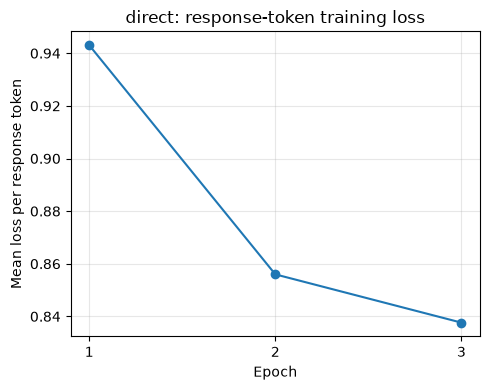

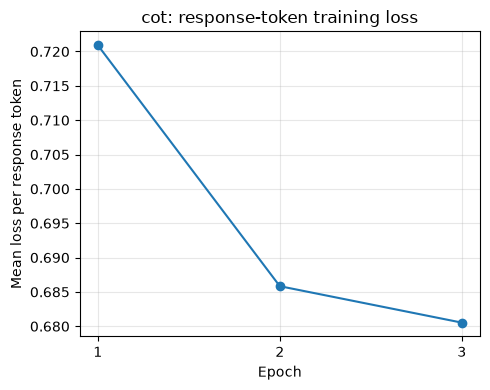

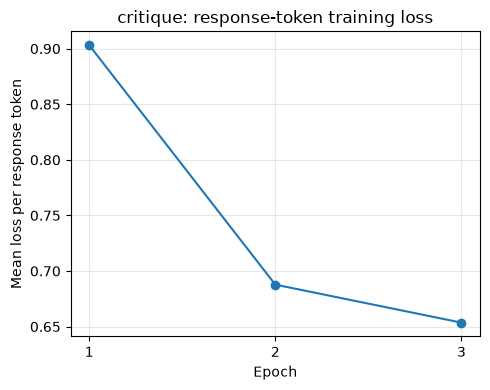

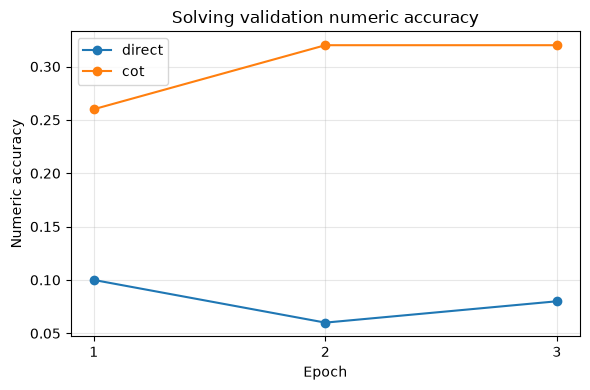

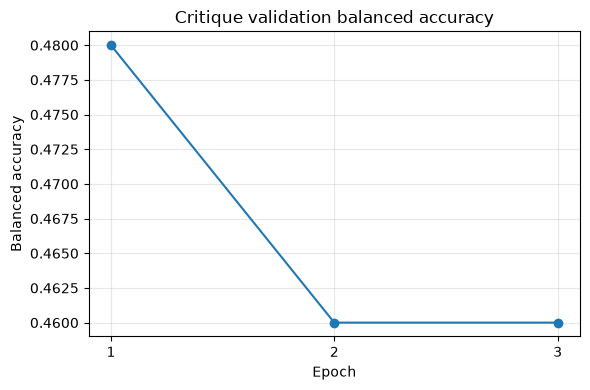

In [12]:
check_scorer_examples()
cfg = configuration()
# Recommended starting settings. Explain any changes to training defaults.
cfg.update(epochs=3, learning_rate=0.003, train_batch_size=2,
           gradient_accumulation=8, eval_batch_size=4)
cfg["data_sha256"] = DATA_SHA256
print("Chosen configuration:", json.dumps(cfg, indent=2))
tokenizer = AutoTokenizer.from_pretrained(cfg["model"], revision=cfg["model_revision"])
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_root = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
out = output_root / "assignment3_cft" / f"run_{stamp}"
results, histories, predictions, pairs = run_study(cfg, tokenizer, COURSE_DATA, out)
tables = make_figures(results, histories, pairs, out)


## Response analysis
Display the five questions, references, candidates and all seven responses required by Q6. Present the full response analyses here; summarize their findings in the separate report without repeating all raw responses.

In [13]:
# Select and display the five examples specified in Q6.

test_examples = COURSE_DATA["splits"]["test"]

correct_examples = [e for e in test_examples if e["verdict"] == "CORRECT"]
incorrect_examples = [e for e in test_examples
                      if e["verdict"] == "INCORRECT" and e["candidate_answer_correct"] is False]
right_answer_bad_reasoning = [e for e in test_examples
                              if e["verdict"] == "INCORRECT" and e["candidate_answer_correct"] is True]

print("Correct-answer / wrong-reasoning candidates in test split:", len(right_answer_bad_reasoning))

selected = correct_examples[:2] + incorrect_examples[:2] + right_answer_bad_reasoning[:1]
if len(selected) != 5:
    raise ValueError("Could not pick five examples")

lookup = {cond: {r["source_id"]: r for r in rows} for cond, rows in predictions.items()}

conditions = ["frozen_direct", "frozen_cot", "tuned_direct", "tuned_cot",
              "tuned_cft_cot", "frozen_critic", "tuned_critic"]

for i, ex in enumerate(selected, 1):
    sid = ex["source_id"]
    print("=" * 100)
    print(f"EXAMPLE {i} | {ex['question_id']} | {sid}")
    print("=" * 100)
    print("QUESTION:\n", ex["question"])
    print("\nREFERENCE SOLUTION:\n", ex["answer"])
    print("\nREFERENCE VERDICT:", ex["verdict"],
          "| FIRST ERROR:", ex["first_error"],
          "| candidate answer correct:", ex["candidate_answer_correct"])
    print("\nREFERENCE CRITIQUE:\n", ex["critique"])
    print("\nCANDIDATE SOLUTION:\n", ex["candidate"])

    for cond in conditions:
        row = lookup[cond][sid]
        print("\n" + "-" * 40, cond, "-" * 40)
        print(row["response"])

        if cond in ("frozen_critic", "tuned_critic"):
            print(f"[verdict={row['verdict']}, first_error={row['first_error']}, "
                  f"verdict_correct={row['verdict_correct']}, joint_correct={row['joint_correct']}, "
                  f"format={row['format_compliant']}]")
        else:
            print(f"[extracted={row['extracted_prediction']}, reference={row['reference']}, "
                  f"correct={row['extracted_correct']}]")
    print()

Correct-answer / wrong-reasoning candidates in test split: 1
EXAMPLE 1 | gsm8k:test:1136 | mr:8c2506ed-84e6-4916-8f0c-c32a98613d00
QUESTION:
 Bob has a certain number of marbles. If he receives 2 dozen more marbles, he will have 60 marbles. If he loses 10 of the marbles he has, how many marbles will Bob have?

REFERENCE SOLUTION:
 Let B be the number of marbles Bob starts with.
2 dozen marbles is 2 * 12 = <<2*12=24>>24 marbles.
So after receiving 2 dozen more marbles, we know B + 24 = 60.
This means B = 60 - 24 = <<60-24=36>>36.
Bob ends with 36 - 10 = <<36-10=26>>26 marbles.
#### 26

REFERENCE VERDICT: CORRECT | FIRST ERROR: None | candidate answer correct: True

REFERENCE CRITIQUE:
 No incorrect step is identified in the candidate solution.

CANDIDATE SOLUTION:
 Step 1: We know that Bob has a certain number of marbles and that he will receive 2 dozen more marbles, which is 2 x 12 = 24 marbles.
Step 2: This will leave Bob with a total of 60 marbles - 24 marbles = 36 marbles.
Step 3: I

## Export results
Include `results.json` with your executed notebook and PDF report in your submission ZIP. It must contain one prediction for each of the 100 test questions under each of the seven evaluation conditions (700 records in total).

In [14]:
path = export_results(out / "results.json", cfg, results, histories, predictions, pairs)
print("Exported", sum(map(len, predictions.values())), "prediction records to", path)


Exported 700 prediction records to /home/shivraj-pg/Assign3/assignment3_cft/run_20261103T160932_491051Z/results.json


In [15]:
total_records = sum(len(rows) for rows in predictions.values())

print("Total prediction records:", total_records)
print("Evaluation conditions:", len(predictions))

for condition, rows in predictions.items():
    unique_ids = {row["source_id"] for row in rows}

    print(
        f"{condition}: {len(rows)} records, "
        f"{len(unique_ids)} unique test questions"
    )

    assert len(rows) == 100, f"{condition} does not have 100 records."
    assert len(unique_ids) == 100, f"{condition} has duplicate source IDs."

assert len(predictions) == 7, "Expected exactly seven evaluation conditions."
assert total_records == 700, f"Expected 700 records, got {total_records}."

print("\nSUCCESS: All seven conditions have 100 unique predictions each.")

Total prediction records: 700
Evaluation conditions: 7
frozen_direct: 100 records, 100 unique test questions
frozen_cot: 100 records, 100 unique test questions
tuned_direct: 100 records, 100 unique test questions
tuned_cot: 100 records, 100 unique test questions
tuned_cft_cot: 100 records, 100 unique test questions
frozen_critic: 100 records, 100 unique test questions
tuned_critic: 100 records, 100 unique test questions

SUCCESS: All seven conditions have 100 unique predictions each.
